<a href="https://colab.research.google.com/github/FatimaZahra-Elatrach/TP-Pretraitement-Dataset-ML/blob/main/TP2_praitretement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving transactions_TP2.csv to transactions_TP2.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("transactions_TP2.csv")
print("Les 5 premières lignes sont :")
display(df.head())
print("\nDimensions du dataset:", df.shape)
print("\nTypes des variables :")
print(df.dtypes)

Les 5 premières lignes sont :


,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0



Dimensions du dataset: (3045, 12)

Types des variables :
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


In [ ]:
missing = pd.DataFrame({
    "Nombre manquant": df.isnull().sum(),
    "Pourcentage (%)": df.isnull().mean() * 100
})
missing = missing.sort_values(
    by="Pourcentage (%)",
    ascending=False
)
display(missing)

,Nombre manquant,Pourcentage (%)
canal,159,5.221675
anciennete_mois,137,4.499179
appareil,122,4.006568
montant_dh,110,3.612479
region,103,3.382594
nb_ops_24h,53,1.740558
id_operation,0,0.000000
id_client,0,0.000000
heure,0,0.000000
international,0,0.000000


In [ ]:
# Nbr de doublons
nb_doublons = df["id_operation"].duplicated().sum()
print("Nombre de doublons :", nb_doublons)

# Suppression des doublons
df = df.drop_duplicates(subset="id_operation")
print("Nombre de lignes restantes :", len(df))

Nombre de doublons : 45
Nombre de lignes restantes : 3000


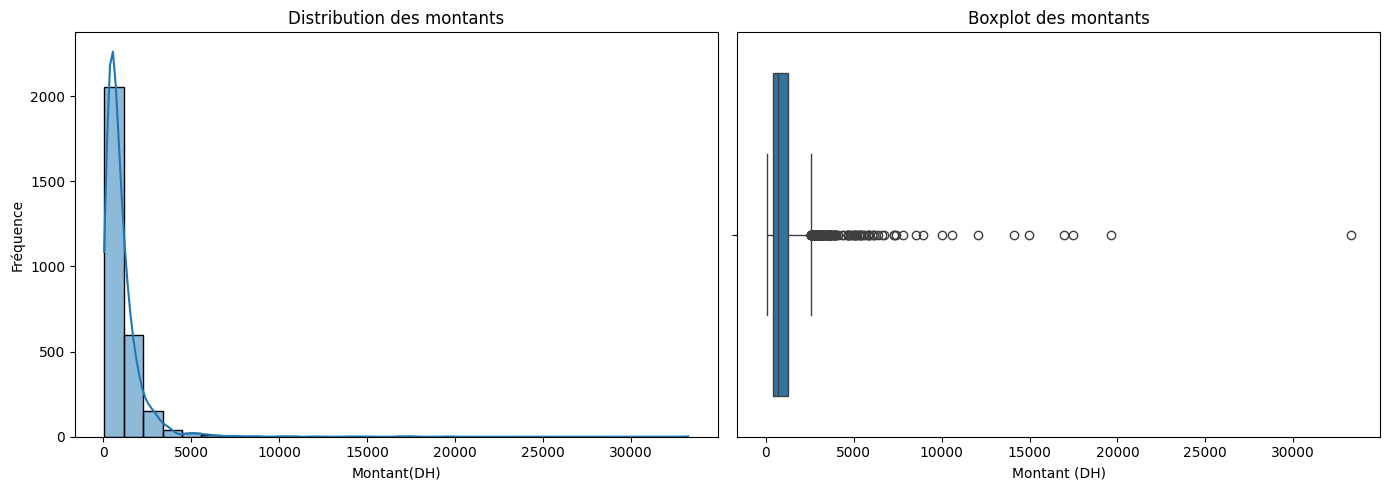

In [ ]:
plt.figure(figsize=(14, 5))
# Histogramme
plt.subplot(1, 2, 1)
sns.histplot(df["montant_dh"].dropna(), bins=30, kde=True)
plt.title("Distribution des montants")
plt.xlabel("Montant(DH)")
plt.ylabel("Fréquence")
# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df["montant_dh"])
plt.title("Boxplot des montants")
plt.xlabel("Montant (DH)")
plt.tight_layout()
plt.show()

In [ ]:
print("Statistiques descriptives :")
display(df["montant_dh"].describe())
print("\nLes 10 montants les plus éleves:")
display(df.nlargest(10, "montant_dh")[["id_operation", "montant_dh"]])

Statistiques descriptives :


,montant_dh
count,2893.000000
mean,1028.359457
std,1320.830647
min,36.410000
25%,389.530000
50%,708.660000
75%,1249.480000
max,33281.230000



Les 10 montants les plus éleves:


,id_operation,montant_dh
2660,OP02851,33281.23
539,OP02169,19658.42
1775,OP00087,17496.64
1557,OP02211,16962.99
2556,OP02832,14951.95
65,OP02462,14135.85
1010,OP01376,12046.21
32,OP00591,10598.93
1313,OP02983,10028.37
2145,OP00127,8910.60


In [ ]:
print("Effectifs des classes")
display(df["fraude"].value_counts())
print("\nProportions des classes (%) :")
display(df["fraude"].value_counts(normalize=True) * 100)

Effectifs des classes


,count
fraude,
0,2742
1,258



Proportions des classes (%) :


,proportion
fraude,
0,91.4
1,8.6


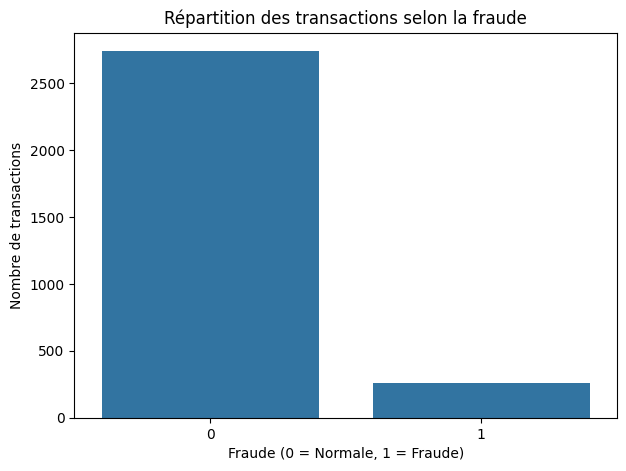

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="fraude")
plt.title("Répartition des transactions selon la fraude")
plt.xlabel("Fraude (0 = Normale, 1 = Fraude)")
plt.ylabel("Nombre de transactions")
plt.show()

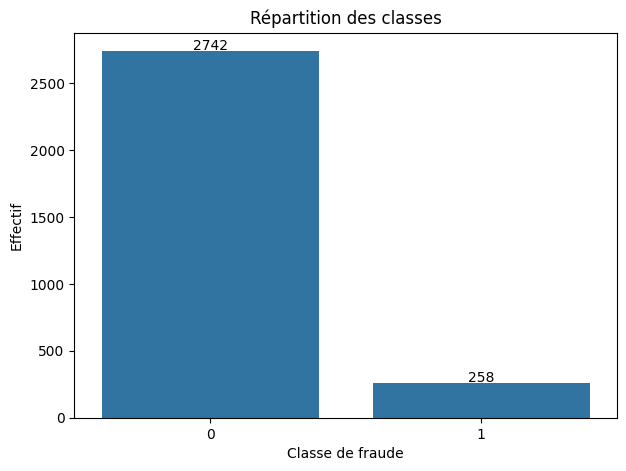

In [ ]:
counts = df["fraude"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=counts.index, y=counts.values)

for i, value in enumerate(counts.values):
    ax.text(i, value + 10, str(value), ha="center")

plt.title("Répartition des classes")
plt.xlabel("Classe de fraude")
plt.ylabel("Effectif")

plt.show()

In [ ]:
print("Colonnes du dataset ")
print(df.columns.tolist())
colonnes_a_exclure = [
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
]
print("\nColonnes à exclure;", colonnes_a_exclure)

Colonnes du dataset 
['id_operation', 'id_client', 'montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international', 'resultat_enquete', 'fraude']

Colonnes à exclure; ['id_operation', 'id_client', 'resultat_enquete', 'fraude']


In [ ]:
colonnes_a_exclure = [
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
]
X = df.drop(columns=colonnes_a_exclure)
y = df["fraude"]
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("\nvariables explicatives :")
print(X.columns.tolist())

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)

variables explicatives :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensons de y_test :", y_test.shape)

print("\nrepartition des classes dans y_train :")
print(y_train.value_counts(normalize=True) * 100)
print("\nRepartition des classes dans y_test :")
print(y_test.value_counts(normalize=True) * 100)

Dimensions de X_train : (2400, 8)
Dimensions de X_test : (600, 8)
Dimensions de y_train : (2400,)
Dimensons de y_test : (600,)

repartition des classes dans y_train :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

Repartition des classes dans y_test :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64


In [ ]:
print("Types de variables :")
display(X_train.dtypes)

Types de variables :


,0
montant_dh,float64
anciennete_mois,float64
nb_ops_24h,float64
heure,int64
canal,object
appareil,object
region,object
international,object


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Var numeriques
numerical_features = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"
]
# Pipeline numerique
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
print("Pipeline numérique créé avec succès.")
print(numeric_pipeline)

Pipeline numérique créé avec succès.
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Var catégor
categorical_features = [
    "canal",
    "appareil",
    "region",
    "international"
]
# Pipeline catégo
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
print("Pipeline catégoriel crée avec succès")
print(categorical_pipeline)

Pipeline catégoriel crée avec succès
Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [ ]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)
print("ColumnTransformer cree avec succes.")
print(preprocessor)

ColumnTransformer cree avec succes.
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['montant_dh', 'anciennete_mois', 'nb_ops_24h',
                                  'heure']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['canal', 'appareil', 'region',
                                  'international'])])


In [ ]:
from sklearn.preprocessing import RobustScaler

robust_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
print("robustScaler pipeline creé avec succes.")

robustScaler pipeline creé avec succes.


In [ ]:
# StandarScaler
X_train_standard = numeric_pipeline.fit_transform(
    X_train[numerical_features]
)
# RobustScaler
X_train_robust = robust_numeric_pipeline.fit_transform(
    X_train[numerical_features]
)
print("standardScaler - premiere ligne :")
print(X_train_standard[0])
print("\nsobustScaler - premiere ligne :")
print(X_train_robust[0])

standardScaler - premiere ligne :
[-0.45279558 -0.69683119  0.16959525  0.64756193]

sobustScaler - premiere ligne :
[-0.35673954 -0.4047619   0.          0.38461538]


In [ ]:
preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)
print("Dimensions après prétraitement :")
print("X_train :", X_train_transformed.shape)
print("X_test :", X_test_transformed.shape)

Dimensions après prétraitement :
X_train : (2400, 18)
X_test : (600, 18)


In [ ]:
# la methode IQR

for col in numerical_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < limite_inf) |
        (X_train[col] > limite_sup)
    ][col].dropna()
    print(f"\nVariable : {col}")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Limite infér :", limite_inf)
    print("Limite supér :", limite_sup)
    print("Nombre d'outliers :", len(outliers))


Variable : montant_dh
Q1 : 393.095
Q3 : 1249.8775
IQR : 856.7825
Limite infér : -892.0787499999999
Limite supér : 2535.05125
Nombre d'outliers : 146

Variable : anciennete_mois
Q1 : 44.0
Q3 : 132.0
IQR : 88.0
Limite infér : -88.0
Limite supér : 264.0
Nombre d'outliers : 0

Variable : nb_ops_24h
Q1 : 1.0
Q3 : 4.0
IQR : 3.0
Limite infér : -3.5
Limite supér : 8.5
Nombre d'outliers : 4

Variable : heure
Q1 : 5.0
Q3 : 18.0
IQR : 13.0
Limite infér : -14.5
Limite supér : 37.5
Nombre d'outliers : 0


In [ ]:
# copie pour appliquer le Capping
X_train_capped = X_train.copy()

for col in numerical_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    X_train_capped[col] = X_train_capped[col].clip(
        lower=limite_inf,
        upper=limite_sup
    )
print("Capping appliqué avec succès.")
print("\nMaximum avant Capping :")
print(X_train[numerical_features].max())
print("\nMaximum après Capping :")
print(X_train_capped[numerical_features].max())

Capping appliqué avec succès.

Maximum avant Capping :
montant_dh         33281.23
anciennete_mois      174.00
nb_ops_24h            11.00
heure                 23.00
dtype: float64

Maximum après Capping :
montant_dh         2535.05125
anciennete_mois     174.00000
nb_ops_24h            8.50000
heure                23.00000
dtype: float64


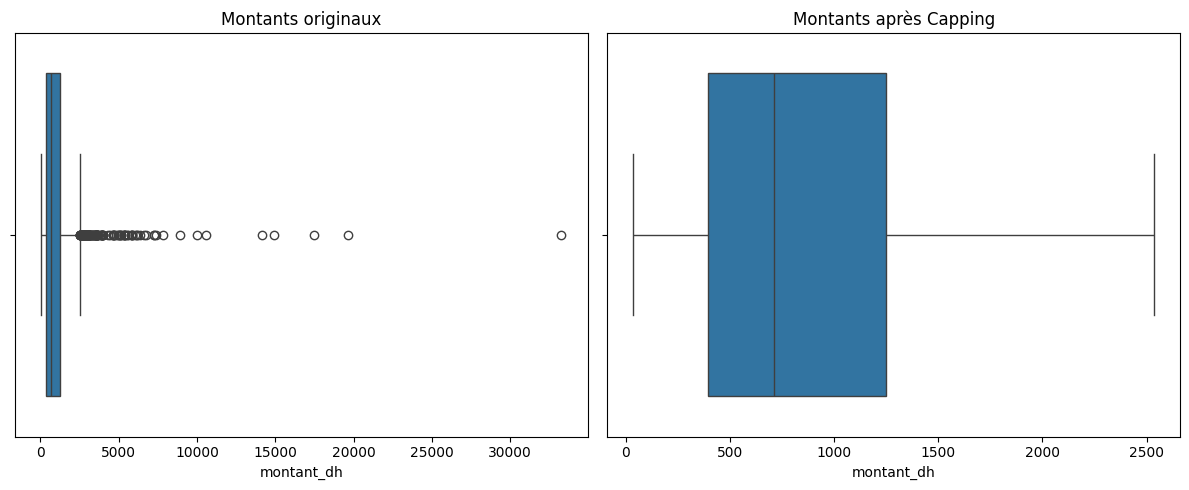

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(x=X_train["montant_dh"])
plt.title("Montants originaux")

plt.subplot(1, 2, 2)
sns.boxplot(x=X_train_capped["montant_dh"])
plt.title("Montants après Capping")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
scalers = {
    "MinMaxScaler": MinMaxScaler(),
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}
montant_train = X_train[["montant_dh"]]
montant_test = X_test[["montant_dh"]]
resultats = {}
for nom, scaler in scalers.items():
    scaler.fit(montant_train)
    train_transforme = scaler.transform(montant_train)
    test_transforme = scaler.transform(montant_test)
    resultats[nom] = {
        "train": train_transforme,
        "test": test_transforme
    }
    print(f"{nom} appliqué avec succès.")
print("\nToutes les transformations sont terminées.")

MinMaxScaler appliqué avec succès.
StandardScaler appliqué avec succès.
RobustScaler appliqué avec succès.

Toutes les transformations sont terminées.


In [ ]:
montants = pd.DataFrame({
    "montant_dh": [
        X_train["montant_dh"].quantile(0.25),
        X_train["montant_dh"].median(),
        X_train["montant_dh"].quantile(0.75),
        X_train["montant_dh"].max()
    ]
})
for nom, scaler in scalers.items():
    montants[nom] = scaler.transform(
        montants[["montant_dh"]]
    ).flatten()
montants = montants.rename(
    columns={"montant_dh": "montant_original"}
)
display(montants.round(4))

,montant_original,MinMaxScaler,StandardScaler,RobustScaler
0,393.0950,0.0107,-0.4732,-0.3708
1,710.7900,0.0203,-0.2381,0.0000
2,1249.8775,0.0365,0.1609,0.6292
3,33281.2300,1.0000,23.8658,38.0148


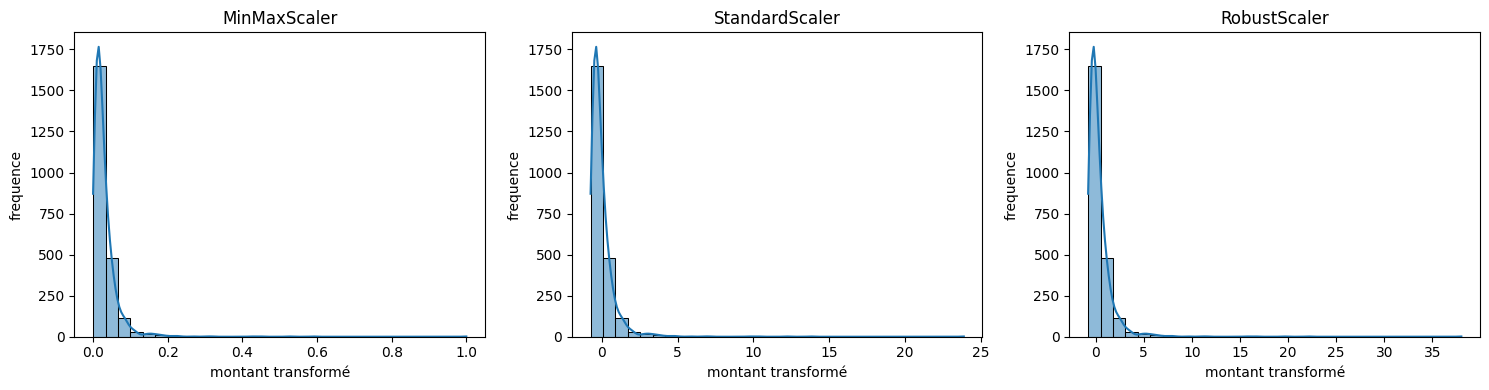

In [ ]:
plt.figure(figsize=(15, 4))

for i, nom in enumerate(
    ["MinMaxScaler", "StandardScaler", "RobustScaler"], 1
):
    plt.subplot(1, 3, i)
    sns.histplot(
        resultats[nom]["train"].flatten(),
        bins=30,
        kde=True
    )
    plt.title(nom)
    plt.xlabel("montant transformé")
    plt.ylabel("frequence")
plt.tight_layout()
plt.show()

In [ ]:
max_train = X_train["montant_dh"].max()
nouveau_montant = max_train + 1000
nouveau_transforme = scalers["MinMaxScaler"].transform(
    pd.DataFrame({"montant_dh": [nouveau_montant]})
)
print("maximum du train :", max_train)
print("nouveau montant :", nouveau_montant)
print("valeur transformée :", nouveau_transforme[0][0])

maximum du train : 33281.23
nouveau montant : 34281.23
valeur transformée : 1.030079874097679


In [ ]:
print("effectifs :")
print(y_train.value_counts().sort_index())
print("\nPourcentages :")
print(y_train.value_counts(normalize=True).sort_index() * 100)

effectifs :
fraude
0    2194
1     206
Name: count, dtype: int64

Pourcentages :
fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64


In [ ]:
!pip install -q imbalanced-learn

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)
print("avant :")
print(y_train.value_counts())
print("\naprès :")
print(y_train_over.value_counts())
print("\ndimensions avant :", X_train.shape)
print("Dimensions apres :", X_train_over.shape)

avant :
fraude
0    2194
1     206
Name: count, dtype: int64

après :
fraude
0    2194
1    2194
Name: count, dtype: int64

dimensions avant : (2400, 8)
Dimensions apres : (4388, 8)


In [ ]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(
    X_train, y_train
)
print("avant :")
print(y_train.value_counts())
print("\naprès :")
print(y_train_under.value_counts())
print("\ndimensions avant :", X_train.shape)
print("dimensions apres :", X_train_under.shape)

avant :
fraude
0    2194
1     206
Name: count, dtype: int64

après :
fraude
0    206
1    206
Name: count, dtype: int64

dimensions avant : (2400, 8)
dimensions apres : (412, 8)


In [ ]:
from imblearn.over_sampling import SMOTE
import pandas as pd

X_demo = pd.DataFrame({
    "x1": [1, 2, 3, 7, 8, 9, 7, 9],
    "x2": [1, 2, 3, 7, 8, 9, 9, 7]
})

y_demo = pd.Series([1, 1, 1, 0, 0, 0, 0, 0])
print("Avant SMOTE :")
print(y_demo.value_counts())
smote = SMOTE(random_state=42, k_neighbors=2)
X_demo_smote, y_demo_smote = smote.fit_resample(
    X_demo, y_demo
)
print("\nApres SMOTE :")
print(y_demo_smote.value_counts())
print("\nnouvelles observations synthetiques :")
display(X_demo_smote.tail(2))

Avant SMOTE :
0    5
1    3
Name: count, dtype: int64

Apres SMOTE :
1    5
0    5
Name: count, dtype: int64

nouvelles observations synthetiques :


,x1,x2
8,2,2
9,2,2


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# Pipeline numériq
final_numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])
#pipeline catégor
final_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
#Pipeline final
final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", final_numeric_pipeline, numerical_features),
        ("cat", final_categorical_pipeline, categorical_features)
    ]
)
print("Pipeline final créé avec succès.")

Pipeline final créé avec succès.


In [ ]:
final_preprocessor.fit(X_train)

# Transformation
X_train_final = final_preprocessor.transform(X_train)
X_test_final = final_preprocessor.transform(X_test)
print("Dimensions train :", X_train_final.shape)
print("Dimensions test :", X_test_final.shape)
# Vérif des valeurs manquantes
from scipy import sparse
import numpy as np
def compter_nan(data):
    if sparse.issparse(data):
        return np.isnan(data.data).sum()
    return np.isnan(data).sum()
print("NaN dans train :", compter_nan(X_train_final))
print("NaN dans test :", compter_nan(X_test_final))

Dimensions train : (2400, 18)
Dimensions test : (600, 18)
NaN dans train : 0
NaN dans test : 0


In [ ]:
import joblib
import numpy as np
from scipy import sparse

joblib.dump(final_preprocessor, "preprocessor_final.joblib")
print("Préprocesseur sauvegardé.")
preprocessor_charge = joblib.load("preprocessor_final.joblib")
print("Préprocesseur chargé.")
echantillon = X_train.iloc[:5]
resultat_original = final_preprocessor.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)
if sparse.issparse(resultat_original):
    resultat_original = resultat_original.toarray()
if sparse.issparse(resultat_charge):
    resultat_charge = resultat_charge.toarray()
print("resultats identiques :",
      np.allclose(resultat_original, resultat_charge))

Préprocesseur sauvegardé.
Préprocesseur chargé.
resultats identiques : True


In [ ]:
from google.colab import files

files.download("preprocessor_final.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>